In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io import arff
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the Iris dataset
data, meta = arff.loadarff("dataset_61_iris.arff")
df = pd.DataFrame(data)

# Convert byte strings to regular strings
for col in df.select_dtypes(["object"]).columns:
    df[col] = df[col].str.decode("utf-8")

print("IRIS DATASET INFORMATION")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

IRIS DATASET INFORMATION
Dataset shape: (150, 5)

First 5 rows:
   sepallength  sepalwidth  petallength  petalwidth        class
0          5.1         3.5          1.4         0.2  Iris-setosa
1          4.9         3.0          1.4         0.2  Iris-setosa
2          4.7         3.2          1.3         0.2  Iris-setosa
3          4.6         3.1          1.5         0.2  Iris-setosa
4          5.0         3.6          1.4         0.2  Iris-setosa

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   sepallength  150 non-null    float64
 1   sepalwidth   150 non-null    float64
 2   petallength  150 non-null    float64
 3   petalwidth   150 non-null    float64
 4   class        150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Missing values:
sepallength    0
sepalwidth     0
petallength    0
petalwidth     0
clas

Number of duplicates: 3

Class distribution:
class
Iris-versicolor    50
Iris-virginica     49
Iris-setosa        48
Name: count, dtype: int64


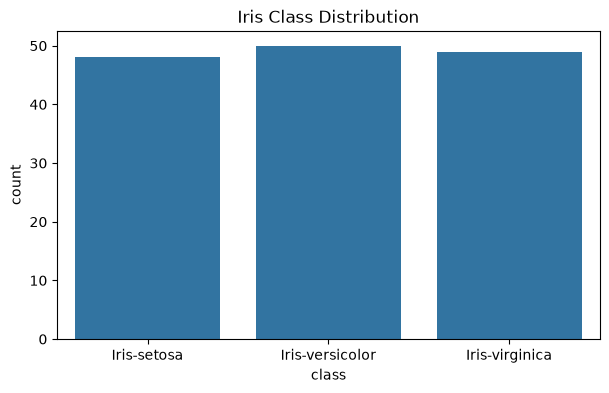

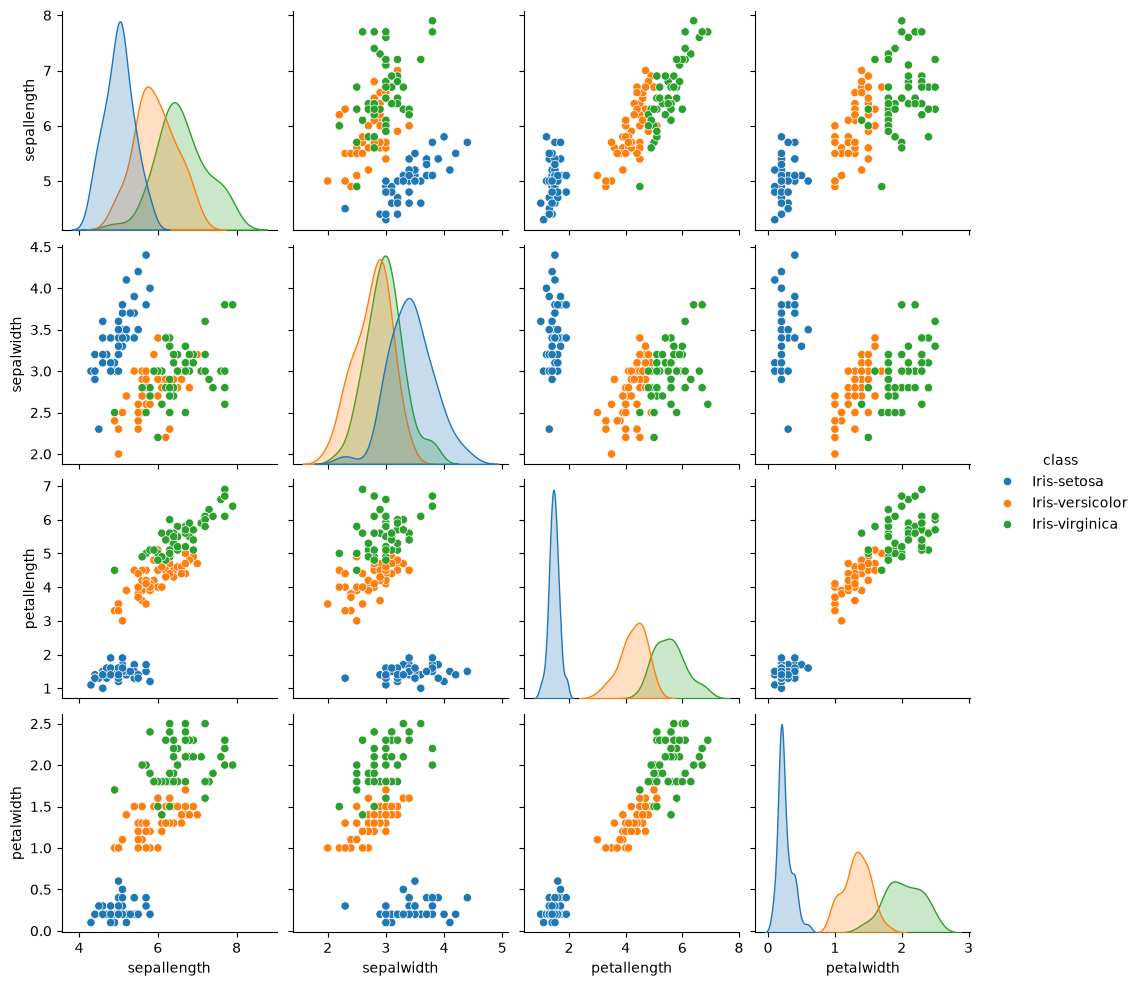

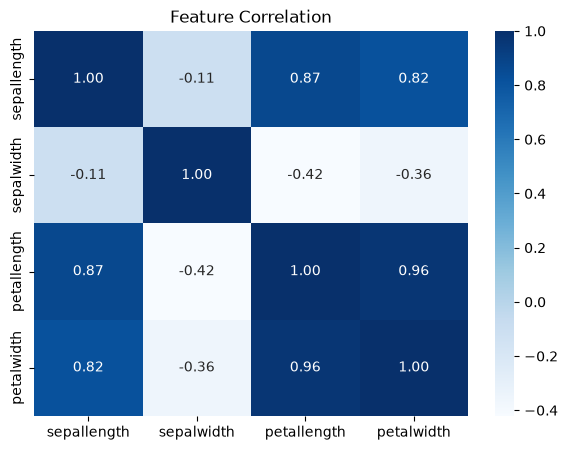

Training samples: 117
Testing samples: 30


In [2]:
# Check and remove duplicate rows
print("Number of duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# Split features and target
X = df.drop("class", axis=1)
y = df["class"]

# Check class distribution
print("\nClass distribution:")
print(y.value_counts())

# Plot class distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="class")
plt.title("Iris Class Distribution")
plt.show()

# Plot feature relationships
sns.pairplot(df, hue="class")
plt.show()

# Plot feature correlation
plt.figure(figsize=(7, 5))
sns.heatmap(X.corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Feature Correlation")
plt.show()

# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

MODEL COMPARISON RESULTS
              Model  Train Accuracy  Test Accuracy  Overfitting Gap
                SVM          0.9744         0.9667           0.0077
  Gradient Boosting          1.0000         0.9667           0.0333
      Random Forest          1.0000         0.9667           0.0333
                KNN          0.9744         0.9333           0.0410
Logistic Regression          0.9573         0.9333           0.0239
      Decision Tree          1.0000         0.9333           0.0667
        Naive Bayes          0.9573         0.9333           0.0239


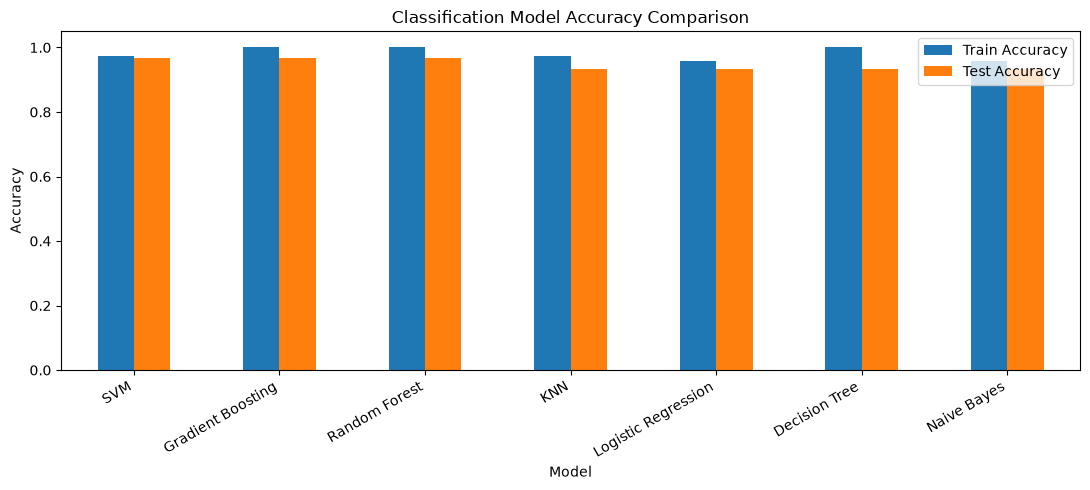

In [3]:
# Define classification models
models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "KNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "SVM": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC(kernel="rbf")
    ),

    "Decision Tree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(random_state=42)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=100, random_state=42)
    ),

    "Naive Bayes": make_pipeline(
        SimpleImputer(strategy="median"),
        GaussianNB()
    ),

    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingClassifier(random_state=42)
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    # Make predictions on training and testing data
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)

    results.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Overfitting Gap": train_acc - test_acc
    })

# Compare model performance
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Test Accuracy", ascending=False
)

print("MODEL COMPARISON RESULTS")
print(results_df.round(4).to_string(index=False))

# Plot model accuracy
results_df.set_index("Model")[
    ["Train Accuracy", "Test Accuracy"]
].plot(kind="bar", figsize=(11, 5))

plt.title("Classification Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# Compare Decision Tree before and after limiting its depth
tree_models = {
    "Original Decision Tree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(random_state=42)
    ),

    "Limited Decision Tree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(
            max_depth=3,
            min_samples_leaf=5,
            random_state=42
        )
    )
}

print("OVERFITTING CHECK")

for name, model in tree_models.items():
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print("\n", name)
    print(f"Train Accuracy: {train_acc * 100:.2f}%")
    print(f"Test Accuracy : {test_acc * 100:.2f}%")
    print(f"Accuracy Gap  : {(train_acc - test_acc) * 100:.2f}%")

OVERFITTING CHECK

 Original Decision Tree
Train Accuracy: 100.00%
Test Accuracy : 93.33%
Accuracy Gap  : 6.67%

 Limited Decision Tree
Train Accuracy: 96.58%
Test Accuracy : 93.33%
Accuracy Gap  : 3.25%
